## Setup

In [29]:
!pip install -q xgboost lightgbm shap openpyxl

### Import Libraries

In [30]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


## Load Data

In [31]:
file_path = "/content/Telco_customer_churn.xlsx"

df = pd.read_excel(file_path)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


## Initial Data Overview

In [32]:
print("Columns:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Rows:", df.duplicated().sum())

Columns:
['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']

Data Types:


,Data Type
CustomerID,object
Count,int64
Country,object
State,object
City,object
Zip Code,int64
Lat Long,object
Latitude,float64
Longitude,float64
Gender,object



Missing Values:


,Missing Values
CustomerID,0
Count,0
Country,0
State,0
City,0
Zip Code,0
Lat Long,0
Latitude,0
Longitude,0
Gender,0



Duplicate Rows: 0


## Data Cleaning and Target Preparation

In [33]:
# Clean column names
df.columns = df.columns.str.strip()

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Identify target
target_column = "Churn Label"

if target_column not in df.columns:
    raise ValueError(f"{target_column} not found. Available columns: {df.columns.tolist()}")

# Convert target
df[target_column] = (
    df[target_column]
    .astype(str)
    .str.strip()
    .map({"Yes": 1, "No": 0})
)

# Remove rows with missing target
df = df.dropna(subset=[target_column])

df[target_column] = df[target_column].astype(int)

print("Cleaned Shape:", df.shape)
print("\nTarget Distribution:")
display(df[target_column].value_counts().rename({0: "No Churn", 1: "Churn"}))

Cleaned Shape: (7043, 33)

Target Distribution:


,count
Churn Label,
No Churn,5174
Churn,1869


## Feature and Target Separation

In [34]:
# Keep Customer ID separately
customer_ids = df["Customer ID"].copy() if "Customer ID" in df.columns else pd.Series(
    range(len(df)),
    index=df.index,
    name="Customer ID"
)

# Columns that can cause target leakage or are not useful for prediction
drop_columns = [
    "Churn Label",
    "Churn Value",
    "Churn Score",
    "Churn Reason",
    "Churn Category",
    "Customer Status",
    "CLTV",
    "Customer ID",
    "Count",
    "Quarter"
]

drop_columns = [col for col in drop_columns if col in df.columns]

X = df.drop(columns=drop_columns)
y = df["Churn Label"]

print("Removed Columns:")
print(drop_columns)

print("\nFeature Shape:", X.shape)

Removed Columns:
['Churn Label', 'Churn Value', 'Churn Score', 'Churn Reason', 'CLTV', 'Count']

Feature Shape: (7043, 27)


## Data Preprocessing

In [35]:
# Strip whitespace from object columns
for col in X.select_dtypes(include="object").columns:
    X[col] = X[col].astype(str).str.strip()

# Convert Total Charges if available
if "Total Charges" in X.columns:
    X["Total Charges"] = pd.to_numeric(
        X["Total Charges"],
        errors="coerce"
    )

# Remove constant columns
constant_columns = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

if constant_columns:
    X = X.drop(columns=constant_columns)

print("Constant Columns Removed:", constant_columns)
print("Final Feature Shape:", X.shape)

Constant Columns Removed: ['Country', 'State']
Final Feature Shape: (7043, 25)


## Exploratory Data Analysis (EDA)

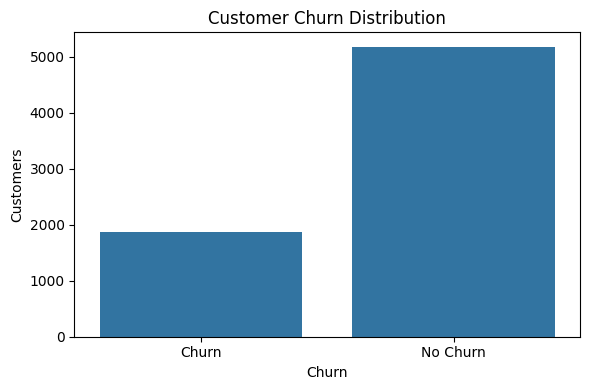

Churn Percentage: 26.54 %


In [36]:
plt.figure(figsize=(6, 4))

sns.countplot(
    x=y.map({0: "No Churn", 1: "Churn"})
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Customers")
plt.tight_layout()
plt.show()

print("Churn Percentage:", round(y.mean() * 100, 2), "%")

### Churn Rate by Key Categorical Features

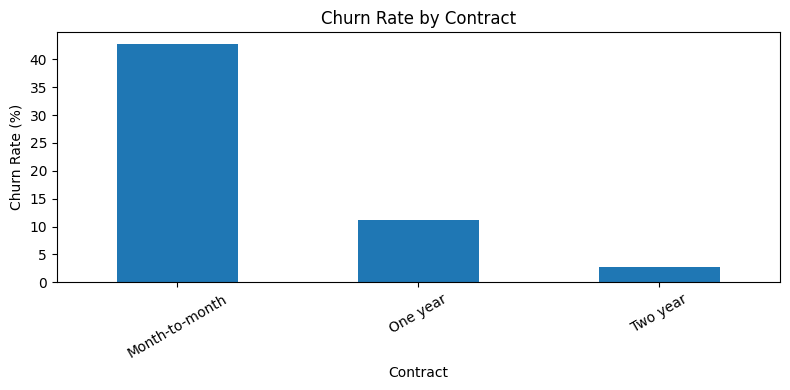

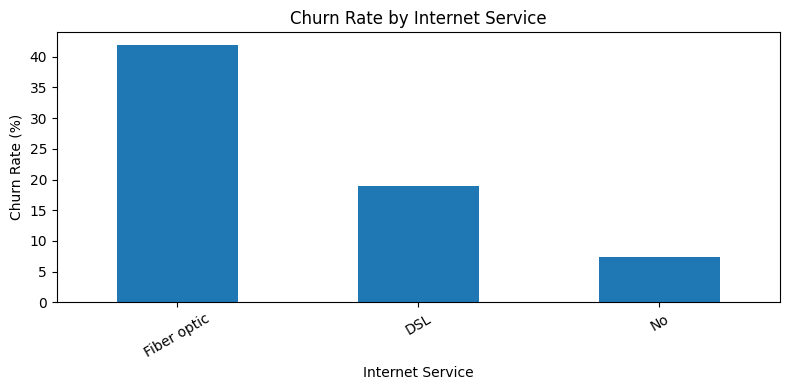

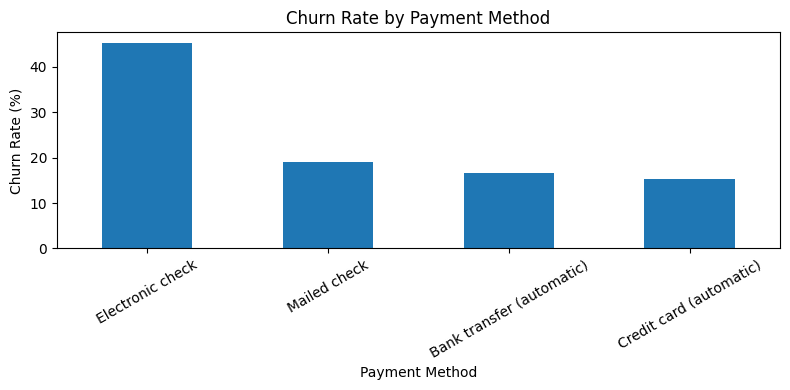

In [37]:
eda_columns = [
    "Contract",
    "Internet Service",
    "Payment Method"
]

for col in eda_columns:
    if col in X.columns:
        plt.figure(figsize=(8, 4))

        churn_rate = (
            pd.crosstab(
                X[col],
                y,
                normalize="index"
            )[1] * 100
        ).sort_values(ascending=False)

        churn_rate.plot(kind="bar")

        plt.title(f"Churn Rate by {col}")
        plt.xlabel(col)
        plt.ylabel("Churn Rate (%)")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()

## Feature Engineering

In [38]:
# Service count
service_columns = [
    "Phone Service",
    "Multiple Lines",
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Tech Support",
    "Streaming TV",
    "Streaming Movies"
]

available_services = [
    col for col in service_columns
    if col in X.columns
]

if available_services:
    X["ServiceCount"] = 0

    for col in available_services:
        X["ServiceCount"] += (
            X[col]
            .astype(str)
            .str.lower()
            .eq("yes")
            .astype(int)
        )

# Tenure group
if "Tenure Months" in X.columns:
    X["TenureGroup"] = pd.cut(
        X["Tenure Months"],
        bins=[-1, 12, 36, np.inf],
        labels=["New", "Medium", "Long-term"]
    )

print("Feature Engineering Completed")
print("\nFeatures:")
print(X.columns.tolist())

Feature Engineering Completed

Features:
['CustomerID', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'ServiceCount', 'TenureGroup']


## Data Splitting

In [39]:
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X,
    y,
    customer_ids,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nTraining Churn Rate:", round(y_train.mean() * 100, 2), "%")
print("Testing Churn Rate:", round(y_test.mean() * 100, 2), "%")

Training Shape: (5634, 27)
Testing Shape: (1409, 27)

Training Churn Rate: 26.54 %
Testing Churn Rate: 26.54 %


## Preprocessing Pipeline

In [40]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Processed Training Shape: (5634, 8465)
Processed Testing Shape: (1409, 8465)


## Model Evaluation Function

In [60]:
results = {}

def evaluate_model(name, model):
    train_pred = model.predict(X_train_processed)
    test_pred = model.predict(X_test_processed)

    if hasattr(model, "predict_proba"):
        test_prob = model.predict_proba(X_test_processed)[:, 1]
    else:
        test_prob = test_pred

    train_accuracy = accuracy_score(y_train, train_pred)
    test_accuracy = accuracy_score(y_test, test_pred)
    precision = precision_score(y_test, test_pred, zero_division=0)
    recall = recall_score(y_test, test_pred, zero_division=0)
    f1 = f1_score(y_test, test_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, test_prob)

    results[name] = {
        "Model": name,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "ROC-AUC": roc_auc,
        "Train-Test Gap": train_accuracy - test_accuracy
    }

    print(f"\n{name}")
    print("-" * 40)
    print(f"Train Accuracy : {train_accuracy:.4f}")
    print(f"Test Accuracy  : {test_accuracy:.4f}")
    print(f"Precision      : {precision:.4f}")
    print(f"Recall         : {recall:.4f}")
    print(f"F1-score       : {f1:.4f}")
    print(f"ROC-AUC        : {roc_auc:.4f}")
    print(f"Train-Test Gap : {train_accuracy - test_accuracy:.4f}")

### Re-initializing Training Data

It appears that `X_train_processed` and `y_train` were lost from the kernel state. This cell re-executes the data splitting and preprocessing steps to ensure these variables are properly defined for model training.

In [42]:
# Re-running data splitting and preprocessing to ensure X_train_processed and y_train are defined.
# This is necessary because these variables appear to be missing from the kernel state,
# likely due to a kernel reset or intermittent issue, despite previous cells indicating
# successful execution.

import pandas as pd # Ensure pandas is available
import numpy as np # Ensure numpy is available for np.inf
from sklearn.model_selection import train_test_split # Explicitly import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Define RANDOM_STATE if it's not already defined (ensuring robustness)
if 'RANDOM_STATE' not in globals():
    RANDOM_STATE = 42

# --- Replicate Data Loading (from cell 2tkotjzuwskW) ---
file_path = "/content/Telco_customer_churn.xlsx"
df = pd.read_excel(file_path)

# --- Replicate Data Cleaning and Target Preparation (from cell kM2OV0clxMD_) ---
df.columns = df.columns.str.strip()
df = df.drop_duplicates().reset_index(drop=True)
target_column = "Churn Label"
df[target_column] = (
    df[target_column]
    .astype(str)
    .str.strip()
    .map({"Yes": 1, "No": 0})
)
df = df.dropna(subset=[target_column])
df[target_column] = df[target_column].astype(int)

# --- Replicate Feature and Target Separation (from cell GPSgTgpYxRbT) ---
# Keep Customer ID separately
customer_ids = df["Customer ID"].copy() if "Customer ID" in df.columns else pd.Series(
    range(len(df)),
    index=df.index,
    name="Customer ID"
)

# Columns that can cause target leakage or are not useful for prediction
drop_columns = [
    "Churn Label",
    "Churn Value",
    "Churn Score",
    "Churn Reason",
    "Churn Category",
    "Customer Status",
    "CLTV",
    "Customer ID",
    "Count",
    "Quarter"
]

drop_columns = [col for col in drop_columns if col in df.columns]

X = df.drop(columns=drop_columns)
y = df["Churn Label"]

# --- Replicate Data Preprocessing (from cell HCajjcjKxWM0) ---
# Strip whitespace from object columns
for col in X.select_dtypes(include="object").columns:
    X[col] = X[col].astype(str).str.strip()

# Convert Total Charges if available
if "Total Charges" in X.columns:
    X["Total Charges"] = pd.to_numeric(
        X["Total Charges"],
        errors="coerce"
    )

# Remove constant columns
constant_columns = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

if constant_columns:
    X = X.drop(columns=constant_columns)

# --- Replicate Data Splitting (from cell Az67rRY93xr2) ---
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X,
    y,
    customer_ids,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

# --- Replicate Preprocessing Pipeline (from cell TeuyHGFw3xTo) ---
numeric_features = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Data splitting and preprocessing re-executed to ensure variables are defined.")
print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Data splitting and preprocessing re-executed to ensure variables are defined.
Processed Training Shape: (5634, 8461)
Processed Testing Shape: (1409, 8461)


In [43]:
# Re-initializing 'results' dictionary and 'evaluate_model' function due to NameError
# This ensures the model evaluation function is available after data preprocessing
# and before model training, robust to kernel state issues.

# Explicitly import necessary metrics for evaluate_model function
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

results = {}

def evaluate_model(name, model):
    train_pred = model.predict(X_train_processed)
    test_pred = model.predict(X_test_processed)

    if hasattr(model, "predict_proba"):
        test_prob = model.predict_proba(X_test_processed)[:, 1]
    else:
        test_prob = test_pred

    train_accuracy = accuracy_score(y_train, train_pred)
    test_accuracy = accuracy_score(y_test, test_pred)
    precision = precision_score(y_test, test_pred, zero_division=0)
    recall = recall_score(y_test, test_pred, zero_division=0)
    f1 = f1_score(y_test, test_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, test_prob)

    results[name] = {
        "Model": name,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "ROC-AUC": roc_auc,
        "Train-Test Gap": train_accuracy - test_accuracy
    }

    print(f"\n{name}")
    print("-" * 40)
    print(f"Train Accuracy : {train_accuracy:.4f}")
    print(f"Test Accuracy  : {test_accuracy:.4f}")
    print(f"Precision      : {precision:.4f}")
    print(f"Recall         : {recall:.4f}")
    print(f"F1-score       : {f1:.4f}")
    print(f"ROC-AUC        : {roc_auc:.4f}")
    print(f"Train-Test Gap : {train_accuracy - test_accuracy:.4f}")

print("'evaluate_model' function and 'results' dictionary re-initialized.")

'evaluate_model' function and 'results' dictionary re-initialized.


In [44]:
logistic_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

logistic_model.fit(
    X_train_processed,
    y_train
)

evaluate_model(
    "Logistic Regression",
    logistic_model
)


Logistic Regression
----------------------------------------
Train Accuracy : 0.9022
Test Accuracy  : 0.7566
Precision      : 0.5311
Recall         : 0.7086
F1-score       : 0.6071
ROC-AUC        : 0.8332
Train-Test Gap : 0.1456


### Random Forest Classifier

In [45]:
rf = RandomForestClassifier(
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_params = {
    "n_estimators": [200, 300],
    "max_depth": [None, 10, 15],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"]
}

rf_search = RandomizedSearchCV(
    rf,
    rf_params,
    n_iter=8,
    scoring="f1",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=0
)

rf_search.fit(
    X_train_processed,
    y_train
)

rf_model = rf_search.best_estimator_

print("Best Random Forest Parameters:")
print(rf_search.best_params_)

evaluate_model(
    "Random Forest",
    rf_model
)

Best Random Forest Parameters:
{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 15}

Random Forest
----------------------------------------
Train Accuracy : 0.7584
Test Accuracy  : 0.7388
Precision      : 0.5050
Recall         : 0.8075
F1-score       : 0.6214
ROC-AUC        : 0.8303
Train-Test Gap : 0.0196


### XGBoost Classifier

In [46]:
xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method="hist"
)

xgb_params = {
    "n_estimators": [150, 200, 300],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

xgb_search = RandomizedSearchCV(
    xgb,
    xgb_params,
    n_iter=8,
    scoring="f1",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=0
)

xgb_search.fit(
    X_train_processed,
    y_train
)

xgb_model = xgb_search.best_estimator_

print("Best XGBoost Parameters:")
print(xgb_search.best_params_)

evaluate_model(
    "XGBoost",
    xgb_model
)

Best XGBoost Parameters:
{'subsample': 0.8, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.8}

XGBoost
----------------------------------------
Train Accuracy : 0.8342
Test Accuracy  : 0.7991
Precision      : 0.6454
Recall         : 0.5401
F1-score       : 0.5881
ROC-AUC        : 0.8555
Train-Test Gap : 0.0351


### LightGBM Classifier

In [47]:
# LightGBM

import re

# Clean feature names for LightGBM
def clean_lgbm_feature_names(columns):
    cleaned = []

    for col in columns:
        col = str(col)

        # Replace all characters except letters, numbers and underscore
        col = re.sub(r"[^A-Za-z0-9_]", "_", col)

        # Remove repeated underscores
        col = re.sub(r"_+", "_", col)

        # Remove leading/trailing underscores
        col = col.strip("_")

        if not col:
            col = "feature"

        cleaned.append(col)

    # Make duplicate names unique
    used = {}
    final_names = []

    for col in cleaned:
        if col not in used:
            used[col] = 0
            final_names.append(col)
        else:
            used[col] += 1
            final_names.append(f"{col}_{used[col]}")

    return final_names


# Apply safe feature names
safe_feature_names = clean_lgbm_feature_names(
    X_train_processed.columns
)

X_train_processed.columns = safe_feature_names
X_test_processed.columns = safe_feature_names

# Update feature names for later SHAP/feature importance use
feature_names = safe_feature_names

print("Feature names cleaned for LightGBM.")
print("Number of features:", len(feature_names))


# LightGBM model
lgbm = LGBMClassifier(
    objective="binary",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1,
    class_weight="balanced"
)


# Small and fast parameter search
lgbm_params = {
    "n_estimators": [100, 150, 200],
    "num_leaves": [15, 31, 50],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [-1, 5, 10]
}


lgbm_search = RandomizedSearchCV(
    estimator=lgbm,
    param_distributions=lgbm_params,
    n_iter=8,
    scoring="f1",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=0,
    error_score="raise"
)


# Train
lgbm_search.fit(
    X_train_processed,
    y_train
)


# Best model
lgbm_model = lgbm_search.best_estimator_


print("Best LightGBM Parameters:")
print(lgbm_search.best_params_)


# Evaluate
evaluate_model(
    "LightGBM",
    lgbm_model
)

Feature names cleaned for LightGBM.
Number of features: 8461
Best LightGBM Parameters:
{'num_leaves': 15, 'n_estimators': 100, 'max_depth': -1, 'learning_rate': 0.03}

LightGBM
----------------------------------------
Train Accuracy : 0.7884
Test Accuracy  : 0.7551
Precision      : 0.5254
Recall         : 0.8021
F1-score       : 0.6349
ROC-AUC        : 0.8577
Train-Test Gap : 0.0333


Model Comparison

In [48]:
# Model Comparison
import pandas as pd # Ensure pandas is available locally

# Defensive initialization if results is not defined (e.g., kernel reset)
if 'results' not in globals():
    results = {}

# Define the expected columns for results_df to prevent KeyError when sorting
expected_columns = [
    "Model",
    "Train Accuracy",
    "Test Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "Train-Test Gap"
]

# Check if results is empty and create an empty DataFrame with expected columns if so
if not results:
    results_df = pd.DataFrame(columns=expected_columns)
else:
    results_df = pd.DataFrame(results.values())

# Only sort if the DataFrame is not empty (i.e., if models were actually evaluated)
if not results_df.empty:
    results_df = results_df.sort_values(
        by=["F1-score", "Test Accuracy"],
        ascending=False
    ).reset_index(drop=True)

display(
    results_df.style.format({
        "Train Accuracy": "{:.2%}",
        "Test Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-score": "{:.2%}",
        "ROC-AUC": "{:.4f}",
        "Train-Test Gap": "{:.2%}"
    })
)


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-score,ROC-AUC,Train-Test Gap
0,LightGBM,78.84%,75.51%,52.54%,80.21%,63.49%,0.8577,3.33%
1,Random Forest,75.84%,73.88%,50.50%,80.75%,62.14%,0.8303,1.96%
2,Logistic Regression,90.22%,75.66%,53.11%,70.86%,60.71%,0.8332,14.56%
3,XGBoost,83.42%,79.91%,64.54%,54.01%,58.81%,0.8555,3.51%


### Accuracy Comparison Plot

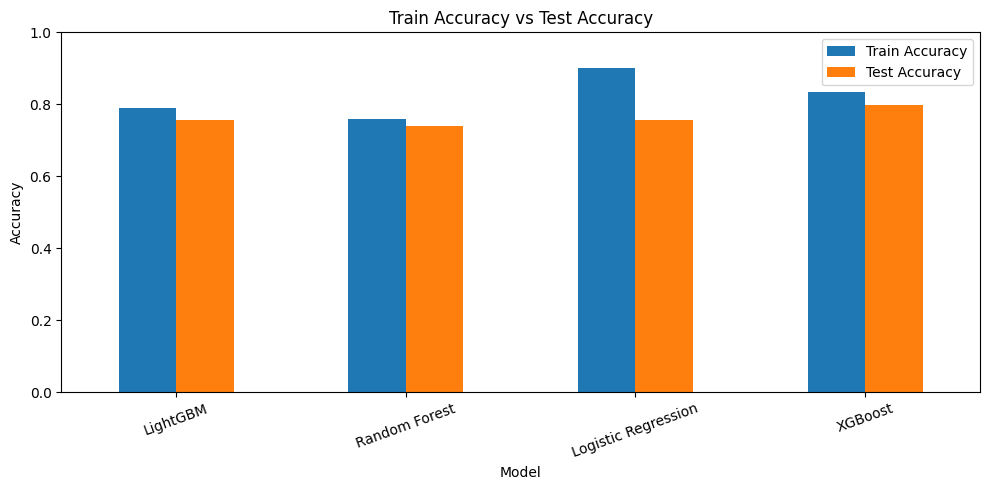

In [49]:
import matplotlib.pyplot as plt # Ensure plt is defined for plotting

plot_df = results_df.set_index("Model")[
    ["Train Accuracy", "Test Accuracy"]
]

plot_df.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Train Accuracy vs Test Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### F1-score Comparison Plot

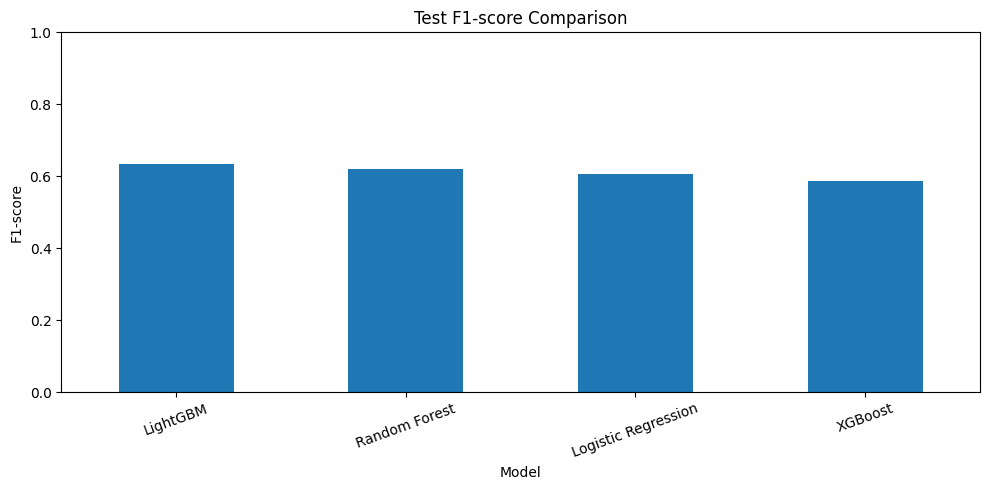

In [50]:
plot_df = results_df.set_index("Model")[
    ["F1-score"]
]

plot_df.plot(
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Test F1-score Comparison")
plt.ylabel("F1-score")
plt.ylim(0, 1) # F1-score is between 0 and 1
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Best Model Selection

In [51]:
model_objects = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "LightGBM": lgbm_model
}

best_model_name = results_df.iloc[0]["Model"]
best_model = model_objects[best_model_name]

best_row = results_df.iloc[0]

print("BEST MODEL")
print("=" * 40)
print("Model          :", best_model_name)
print("Train Accuracy :", f"{best_row['Train Accuracy']:.2%}")
print("Test Accuracy  :", f"{best_row['Test Accuracy']:.2%}")
print("Precision      :", f"{best_row['Precision']:.2%}")
print("Recall         :", f"{best_row['Recall']:.2%}")
print("F1-score       :", f"{best_row['F1-score']:.2%}")
print("ROC-AUC        :", f"{best_row['ROC-AUC']:.4f}")
print("Train-Test Gap :", f"{best_row['Train-Test Gap']:.2%}")

BEST MODEL
Model          : LightGBM
Train Accuracy : 78.84%
Test Accuracy  : 75.51%
Precision      : 52.54%
Recall         : 80.21%
F1-score       : 63.49%
ROC-AUC        : 0.8577
Train-Test Gap : 3.33%


### Confusion Matrix

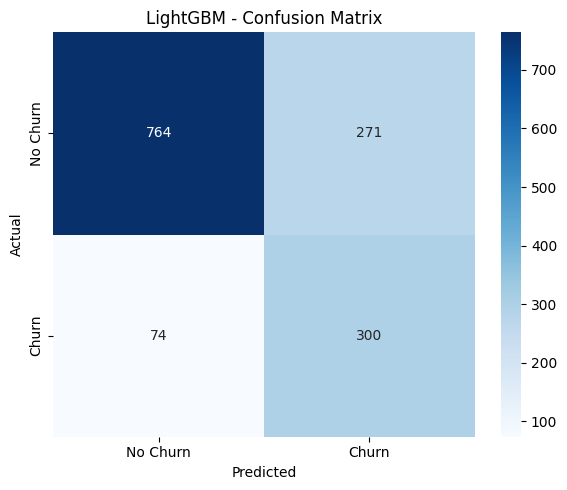

TN: 764
FP: 271
FN: 74
TP: 300


In [52]:
best_test_pred = best_model.predict(X_test_processed)

cm = confusion_matrix(
    y_test,
    best_test_pred
)

tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title(f"{best_model_name} - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

### ROC Curve

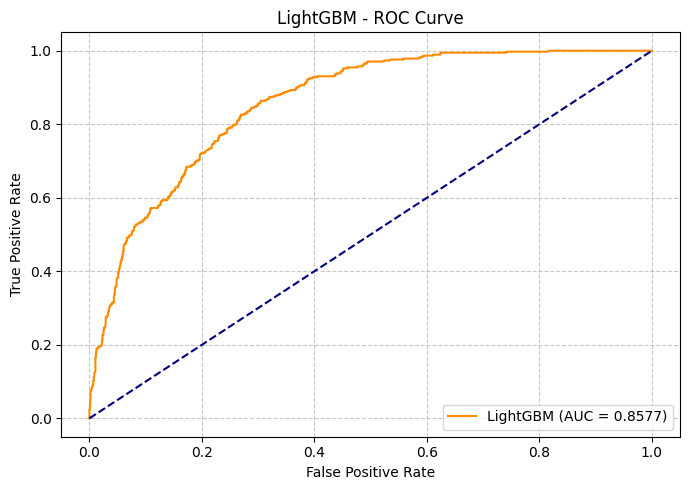

In [61]:
best_test_prob = best_model.predict_proba(
    X_test_processed
)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    best_test_prob
)

roc_auc = roc_auc_score(
    y_test,
    best_test_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    color='darkorange', # Set a distinct color for the ROC curve
    label=f"{best_model_name} (AUC = {roc_auc:.4f})" # Include model name in legend
)

plt.plot(
    [0, 1],
    [0, 1],
    color='navy', # Set a color for the random classifier line
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"{best_model_name} - ROC Curve")
plt.legend(loc="lower right") # Position legend for better visibility
plt.grid(True, linestyle='--', alpha=0.7) # Add a grid for readability
plt.tight_layout()
plt.show()

### Churn Probability Predictions

In [54]:
test_probabilities = best_model.predict_proba(
    X_test_processed
)[:, 1]

test_predictions = (
    test_probabilities >= 0.50
).astype(int)

churn_predictions = pd.DataFrame({
    "Customer ID": id_test.values,
    "Churn Probability": test_probabilities,
    "Prediction": np.where(
        test_predictions == 1,
        "Churn",
        "No Churn"
    )
})

churn_predictions = churn_predictions.sort_values(
    "Churn Probability",
    ascending=False
).reset_index(drop=True)

display(churn_predictions.head(20))

,Customer ID,Churn Probability,Prediction
0,1818,0.908579,Churn
1,886,0.908579,Churn
2,1203,0.908284,Churn
3,641,0.908050,Churn
4,1756,0.908050,Churn
5,579,0.904713,Churn
6,158,0.904354,Churn
7,623,0.904354,Churn
8,1570,0.904354,Churn
9,6213,0.903326,Churn


### Risk Level Assignment

In [55]:
def risk_level(probability):
    if probability < 0.30:
        return "Low Risk"
    elif probability <= 0.60:
        return "Medium Risk"
    else:
        return "High Risk"


churn_predictions["Risk Level"] = (
    churn_predictions["Churn Probability"]
    .apply(risk_level)
)

display(churn_predictions.head(20))

,Customer ID,Churn Probability,Prediction,Risk Level
0,1818,0.908579,Churn,High Risk
1,886,0.908579,Churn,High Risk
2,1203,0.908284,Churn,High Risk
3,641,0.908050,Churn,High Risk
4,1756,0.908050,Churn,High Risk
5,579,0.904713,Churn,High Risk
6,158,0.904354,Churn,High Risk
7,623,0.904354,Churn,High Risk
8,1570,0.904354,Churn,High Risk
9,6213,0.903326,Churn,High Risk


## Model Explainability (SHAP)

SHAP Shape: (300, 8461)
Feature Shape: (300, 8461)


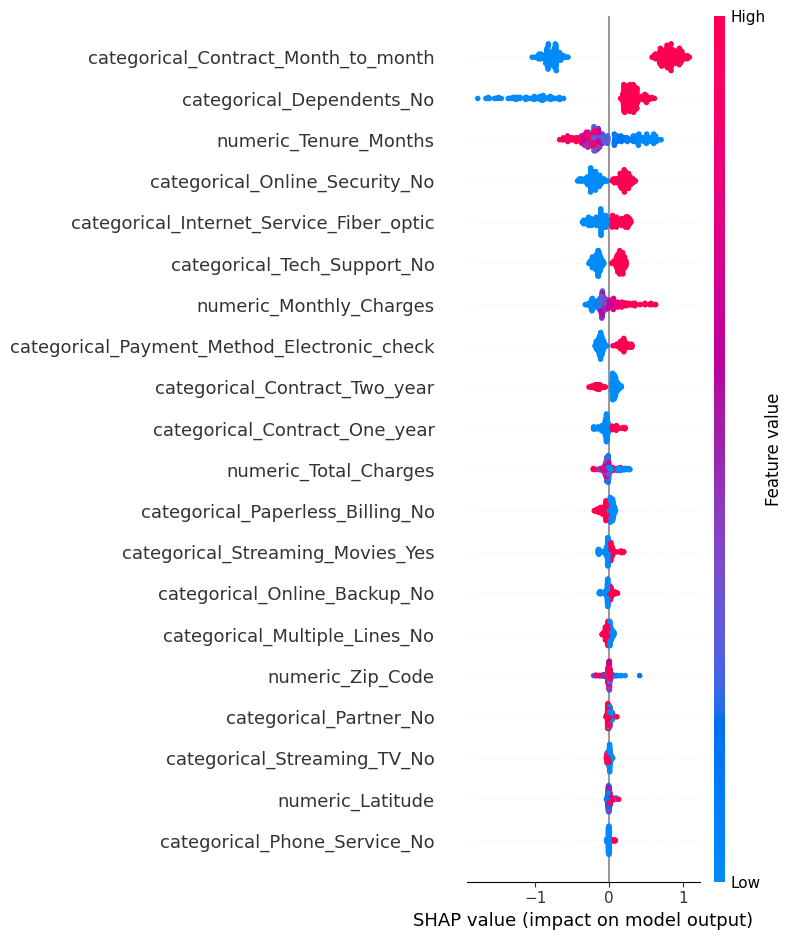

In [56]:
# SHAP Explainability

# Use a small sample for speed
shap_sample = X_test_processed.iloc[
    :min(300, len(X_test_processed))
].copy()

if isinstance(
    best_model,
    (
        RandomForestClassifier,
        XGBClassifier,
        LGBMClassifier
    )
):
    explainer = shap.TreeExplainer(best_model)

    shap_output = explainer.shap_values(
        shap_sample
    )

    if isinstance(shap_output, list):
        shap_values = np.asarray(shap_output[-1])
    else:
        shap_output = np.asarray(shap_output)

        if shap_output.ndim == 2:
            shap_values = shap_output

        elif shap_output.ndim == 3:
            if shap_output.shape[2] == 2:
                shap_values = shap_output[:, :, 1]
            elif shap_output.shape[1] == 2:
                shap_values = shap_output[:, 1, :]
            else:
                shap_values = shap_output[:, :, 0]

        else:
            raise ValueError(
                f"Unexpected SHAP shape: {shap_output.shape}"
            )

elif isinstance(best_model, LogisticRegression):

    explainer = shap.LinearExplainer(
        best_model,
        X_train_processed
    )

    shap_output = explainer.shap_values(
        shap_sample
    )

    if isinstance(shap_output, list):
        shap_values = np.asarray(shap_output[-1])
    else:
        shap_values = np.asarray(shap_output)

else:
    raise ValueError("Unsupported model for SHAP.")

shap_values = np.asarray(shap_values)

print("SHAP Shape:", shap_values.shape)
print("Feature Shape:", shap_sample.shape)

if shap_values.shape[1] != shap_sample.shape[1]:
    raise ValueError(
        f"SHAP feature mismatch: "
        f"{shap_values.shape[1]} vs "
        f"{shap_sample.shape[1]}"
    )

# Summary plot
plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    shap_sample,
    show=False
)

plt.tight_layout()
plt.show()

### SHAP Importance Table

In [57]:
shap_importance = pd.DataFrame({
    "Feature": shap_sample.columns,
    "Importance": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Importance",
    ascending=False
)

display(shap_importance.head(10))

,Feature,Importance
8452,categorical_Contract_Month_to_month,0.807829
8424,categorical_Dependents_No,0.490179
3,numeric_Tenure_Months,0.285326
8434,categorical_Online_Security_No,0.206964
8432,categorical_Internet_Service_Fiber_optic,0.159869
8443,categorical_Tech_Support_No,0.150319
4,numeric_Monthly_Charges,0.145035
8459,categorical_Payment_Method_Electronic_check,0.142285
8454,categorical_Contract_Two_year,0.095909
8453,categorical_Contract_One_year,0.062827


### Top SHAP Features Plot

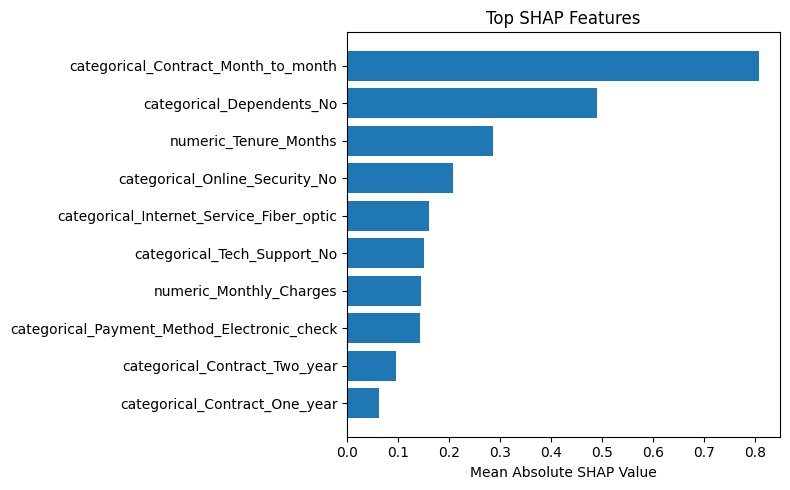

In [58]:
top_shap = shap_importance.head(10).sort_values(
    "Importance"
)

plt.figure(figsize=(8, 5))

plt.barh(
    top_shap["Feature"],
    top_shap["Importance"]
)

plt.title("Top SHAP Features")
plt.xlabel("Mean Absolute SHAP Value")
plt.tight_layout()
plt.show()

## Final Summary

In [59]:
final_results = pd.DataFrame({
    "Metric": [
        "Dataset Rows",
        "Dataset Columns",
        "Best Model",
        "Train Accuracy",
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "Train-Test Gap"
    ],
    "Value": [
        len(df),
        df.shape[1],
        best_model_name,
        f"{best_row['Train Accuracy']:.2%}",
        f"{best_row['Test Accuracy']:.2%}",
        f"{best_row['Precision']:.2%}",
        f"{best_row['Recall']:.2%}",
        f"{best_row['F1-score']:.2%}",
        f"{best_row['ROC-AUC']:.4f}",
        f"{best_row['Train-Test Gap']:.2%}"
    ]
})

display(final_results)

,Metric,Value
0,Dataset Rows,7043
1,Dataset Columns,33
2,Best Model,LightGBM
3,Train Accuracy,78.84%
4,Test Accuracy,75.51%
5,Precision,52.54%
6,Recall,80.21%
7,F1-score,63.49%
8,ROC-AUC,0.8577
9,Train-Test Gap,3.33%
